---
tags:
  - sparse-ad
  - nonlinear
  - viscoelastic
---

# Generalized Maxwell model

!!! info

    This example uses `soldis` solver to solve the nonlinear problem. You can install it via `pip install git+https://github.com/smec-ethz/soldis.git`.


In [1]:
# Only run this if we are in Google Colab
if 'google.colab' in str(get_ipython()):
    print("Installing dependencies using uv...")
    # Install uv if not available
    !pip install -q uv
    # Install system dependencies
    !apt-get install -qq gmsh
    # Use uv to install Python dependencies
    !uv pip install --system matplotlib meshio
    !uv pip install --system "git+https://github.com/smec-ethz/tatva-docs.git"
    !uv pip install --system "git+https://github.com/smec-ethz/soldis.git"
    print("Installation complete!")

We solve a 2D **viscoelastic stress relaxation** problem on a rectangular plate ($0.1 \times 0.2\;\text{m}$) under **plane stress** conditions using a **Generalized Maxwell (Prony series) model** with an arbitrary number $M$ of parallel Maxwell branches. Symmetry boundary conditions are imposed on the left ($u_x = 0$) and bottom ($u_y = 0$) edges, while a constant tensile prestrain $\overline{\varepsilon} = 10^{-3}$ is applied to the top edge ($u_y = \overline{\varepsilon} H$) and held fixed over time ($t \in [0, 0.5]\;\text{s}$). The total axial stress $\sigma_{yy}(t)$ decays according to the Prony series $\sigma_{yy}(t) = E_0 \overline{\varepsilon} + \sum_{k=1}^M E_k \overline{\varepsilon}\exp(-t/\tau_k)$, which is validated against the analytical solution.

**How `tatva` + `soldis` simplify this:**
- `Mesh` + `Operator`: discrete geometry, gradients ($\nabla u$), and quadrature integration ($\int_V \cdot\,dV$).
- `Compound` + `Lifter`: typed nodal fields and automatic separation of free vs. Dirichlet DOFs.
- `jax.vmap` over branches + `jax.grad` + `tatva.sparse`: $M$ Maxwell branches vectorized cleanly inside the energy density, with residual and colored sparse tangent stiffness obtained directly from $\Pi(u)$.
- `soldis`: JIT-compiled sparse Newton solver in pure JAX.

# Libraries

In [2]:
from typing import NamedTuple

import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platforms", "cpu")

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jax import Array
from jax_autovmap import autovmap
from soldis.linear import SparseTatva
from soldis.newton import LineSearchNewtonSolver, LineSearchNewtonSolverOptions

from tatva import Mesh, Operator, compound, element, lifter, linalg, sparse

# Parameters

- **Geometry (`g_p`)**: Plate dimensions (`width`, `height` in m) and structured grid resolution (`Nx`, `Ny`).
- **Material (`m_p`)**: Equilibrium Young's modulus `E_0` (MPa), Poisson's ratio `nu`, and lists `eta_list` ($\text{MPa}\cdot\text{s}$) and `tau_list` (s) defining $M$ parallel Maxwell branches ($E_k = \eta_k / \tau_k$). Edit `eta_list` and `tau_list` to choose any number of Maxwell elements $M$.
- **Time & Loading**: Step size `dt`, total duration `total_time`, and imposed constant prestrain `prestrain` ($u_y = \text{prestrain} \times \text{height}$).

In [3]:
g_p = {
    "width": 0.1,
    "height": 0.2,
    "Nx": 50,
    "Ny": 50,
}

m_p = {
    "E_0": 70e3,
    "nu": 0.3,
    "eta_list": [1e3, 2e3, 5e3],
    "tau_list": [0.02, 0.1, 0.4],
    "plane_stress": True,  # False for plane strain
}

dt = 0.5e-2
total_time = 0.5
Nincr = int(total_time / dt) + 1
time_domain = jnp.linspace(0, total_time, Nincr)

prestrain = 1e-3
total_disp = prestrain * g_p["height"]

# Mesh

`gen_mesh` builds a structured 2D rectangular grid of $(N_x + 1) \times (N_y + 1)$ nodes (`coords` of shape `(n_nodes, 2)`) and splits each cell into two counter-clockwise `Tri3` triangles (`elements` of shape `(2 * Nx * Ny, 3)`). Wrapping them in `tatva.Mesh(coords, elements=elements)` stores the coordinates and connectivity as JAX arrays for `Operator` and `Compound`.

In [4]:
def gen_mesh(width: float, height: float, Nx: int, Ny: int):
    x = np.linspace(0.0, width, Nx + 1)
    y = np.linspace(0.0, height, Ny + 1)
    xv, yv = np.meshgrid(x, y, indexing="ij")
    coords = np.column_stack([xv.ravel(), yv.ravel()])

    i = np.arange(Nx)[:, None]
    j = np.arange(Ny)[None, :]
    n00 = (i * (Ny + 1) + j).ravel()
    n10 = ((i + 1) * (Ny + 1) + j).ravel()
    n01 = (i * (Ny + 1) + (j + 1)).ravel()
    n11 = ((i + 1) * (Ny + 1) + (j + 1)).ravel()

    tris_1 = np.column_stack([n00, n10, n11])
    tris_2 = np.column_stack([n00, n11, n01])
    elements = np.vstack([tris_1, tris_2])
    return coords, elements

In [5]:
coords, elements = gen_mesh(g_p["width"], g_p["height"], g_p["Nx"], g_p["Ny"])

mesh = Mesh(coords, elements=elements)

nb_dofs = 2 * coords.shape[0]
nb_dofs_per_node = coords.shape[1]

gdim = coords.shape[1]
n_elems = mesh.elements.shape[0]

# Operator & Solution Field

- `Operator(mesh, element.Tri3())` provides finite-element spatial derivatives (`op.grad`) and quadrature integration (`op.integrate`) on linear triangular elements.
- `Compound` defines the nodal displacement field $u = (u_x, u_y)$ and maps slice indexing like `Solution.u[nodes, comp]` to global DOF indices.

In [6]:
op = Operator(mesh, element.Tri3())
nb_quads_per_element = len(op.element.quad_points)

In [7]:
class Solution(compound.Compound, mesh=mesh):
    u = compound.field(
        shape=(compound.FieldSize.AUTO, gdim),
        field_type=compound.FieldType.NODAL,
    )

# Boundary conditions

`Lifter` separates the unknown **free DOFs** from constrained **Dirichlet DOFs** and reconstructs the full displacement vector via `lift_from_zeros(u_free)`:

- Symmetry condition on left and bottom edges ($u_x = 0$ on left, $u_y = 0$ on bottom)
- Imposed constant prestrain $u_y = \text{total\_disp}$ on top edge

In [8]:
y_max = jnp.max(mesh.coords[:, 1])
y_min = jnp.min(mesh.coords[:, 1])
x_min = jnp.min(mesh.coords[:, 0])

top_nodes = jnp.where(jnp.isclose(mesh.coords[:, 1], y_max))[0]
bottom_nodes = jnp.where(jnp.isclose(mesh.coords[:, 1], y_min))[0]
left_nodes = jnp.where(jnp.isclose(mesh.coords[:, 0], x_min))[0]

In [9]:
lifter_ = lifter.Lifter(
    Solution.size,
    lifter.Fixed(Solution.u[left_nodes, 0], 0.0),
    lifter.Fixed(Solution.u[bottom_nodes, 1], 0.0),
    lifter.Fixed(Solution.u[top_nodes, 1], total_disp),
)

# Material (Generalized Maxwell / Prony Series)

```text
        ┌─────────[ E_0 ]─────────┐
        ├──[ E_1 ]──┤├─[ η_1 ]────┤
── ε ───┤     ...                 ├─── σ
        └──[ E_M ]──┤├─[ η_M ]────┘
```

Each Maxwell branch $k \in \{1, \dots, M\}$ has stiffness $E_k = \eta_k / \tau_k$ and evolves its own viscous strain $\varepsilon_v^{(k)}$ via the semi-analytical exponential integrator:

$${}^{n+1}\varepsilon_e^{(k)} = {}^{n+1}\varepsilon - {}^{n+1}\varepsilon_v^{(k)} = e^{-\Delta t / (2\tau_k)} \Delta\varepsilon - e^{-\Delta t / \tau_k}\left({}^{n}\varepsilon_v^{(k)} - {}^{n}\varepsilon\right)$$

The total free-energy density sums the equilibrium branch and all $M$ Maxwell springs:

$$\Psi(\varepsilon, \{\varepsilon_e^{(k)}\}_{k=1}^M) = \Psi_e^{(0)}(\varepsilon) + \sum_{k=1}^{M} \Psi_{ve}^{(k)}(\varepsilon_e^{(k)})$$

In [10]:
class Material(NamedTuple):
    mu: float
    lmbda: float
    mu_branches: Array
    lmbda_branches: Array
    eta_branches: Array
    tau_branches: Array
    E_branches: Array
    E_0: float
    n_branches: int

    @classmethod
    def from_youngs_poisson_2d(
        cls,
        E_0: float,
        nu: float,
        eta_list: list[float],
        tau_list: list[float],
        plane_stress: bool = False,
    ) -> "Material":
        assert len(eta_list) == len(tau_list) and len(eta_list) >= 1, (
            "eta_list and tau_list must have the same non-zero length"
        )
        eta_arr = jnp.asarray(eta_list, dtype=jnp.float64)
        tau_arr = jnp.asarray(tau_list, dtype=jnp.float64)
        E_arr = eta_arr / tau_arr

        mu_0 = E_0 / (2 * (1 + nu))
        mu_arr = E_arr / (2 * (1 + nu))

        if plane_stress:
            lmbda_0 = 2 * nu * mu_0 / (1 - nu)
            lmbda_arr = 2 * nu * mu_arr / (1 - nu)
        else:
            lmbda_0 = E_0 * nu / ((1 + nu) * (1 - 2 * nu))
            lmbda_arr = E_arr * nu / ((1 + nu) * (1 - 2 * nu))

        return cls(
            mu=mu_0,
            lmbda=lmbda_0,
            mu_branches=mu_arr,
            lmbda_branches=lmbda_arr,
            eta_branches=eta_arr,
            tau_branches=tau_arr,
            E_branches=E_arr,
            E_0=E_0,
            n_branches=len(eta_list),
        )


mat = Material.from_youngs_poisson_2d(
    m_p["E_0"],
    m_p["nu"],
    m_p["eta_list"],
    m_p["tau_list"],
    m_p["plane_stress"],
)

In [11]:
@autovmap(grad_u=2)
def compute_strain(grad_u):
    return 0.5 * (grad_u + grad_u.T)


@autovmap(eps=2, eps0=2, epsv0=3, dt=0)
def compute_viscoelastic_strain(eps, eps0, epsv0, dt):
    deps = eps - eps0

    def update_branch(epsv0_k, tau_k):
        epsv_k = (
            eps
            + jnp.exp(-dt / tau_k) * (epsv0_k - eps0)
            - jnp.exp(-dt / (2.0 * tau_k)) * deps
        )
        return eps - epsv_k, epsv_k

    return jax.vmap(update_branch, in_axes=(0, 0))(epsv0, mat.tau_branches)


@autovmap(eps=2, eps_e_branches=3)
def strain_energy_density(eps: Array, eps_e_branches: Array) -> Array:
    tr_eps = jnp.trace(eps)
    ed_e0 = (
        mat.mu * linalg.einsum("ij,ij->", eps, eps) + 0.5 * mat.lmbda * tr_eps * tr_eps
    )

    def branch_energy(eps_e_k, mu_k, lmbda_k):
        tr_k = jnp.trace(eps_e_k)
        return (
            mu_k * linalg.einsum("ij,ij->", eps_e_k, eps_e_k)
            + 0.5 * lmbda_k * tr_k * tr_k
        )

    ed_ve = jnp.sum(
        jax.vmap(branch_energy)(eps_e_branches, mat.mu_branches, mat.lmbda_branches)
    )
    return ed_e0 + ed_ve


@autovmap(eps=2, lmbda=0, mu=0)
def compute_stress(eps, lmbda, mu):
    return 2 * mu * eps + lmbda * jnp.trace(eps) * jnp.eye(2)

# Potential Energy & Global AD

In `tatva`, we only need to formulate the scalar potential energy functional:

$$\Pi(u) = \int_V \left(\Psi^e + \sum_{k=1}^M \Psi^{ve}_k\right)\text{d}V$$

Using **global automatic differentiation** directly on $\Pi(u)$, we obtain the internal force vector $f_\text{int} = \frac{\partial \Pi}{\partial u}$ (`jax.grad`) and, in the solver section, the tangent stiffness matrix $K = \frac{\partial r}{\partial u} = -\frac{\partial^2 \Pi}{\partial u^2}$ (`sparse.jacfwd`).

In [12]:
def internal_potential_energy(
    u_full: Array, eps0: Array, epsv0: Array, dt: float
) -> Array:
    u = u_full.reshape(-1, 2)
    grad_u = op.grad(u)
    eps = compute_strain(grad_u)

    eps_e_branches, _ = compute_viscoelastic_strain(eps, eps0, epsv0, dt)
    energy_density = strain_energy_density(eps, eps_e_branches)

    return op.integrate(energy_density)


@jax.jit
def total_energy_free(
    u_free: Array, lifter_obj: lifter.Lifter, eps0: Array, epsv0: Array, dt: float
) -> Array:
    u_full = Solution(lifter_obj.lift_from_zeros(u_free)).u
    return internal_potential_energy(u_full, eps0, epsv0, dt)


compute_internal_free = jax.grad(total_energy_free, argnums=0)

# Solver

`sparse.pattern_from_energy` traces `total_energy_free` to extract the reduced Jacobian sparsity pattern, `ColoredMatrix` + `sparse.jacfwd` computes the sparse tangent stiffness $K = \partial r/\partial u_\text{free}$ via graph coloring, and `LineSearchNewtonSolver` + `SparseTatva()` solves the system (compiled once with `jax.jit`).

In [13]:
@jax.jit
def fn(
    u: Array,
    lifter_obj: lifter.Lifter,
    fext: Array,
    eps0: Array,
    epsv0: Array,
    dt: float,
) -> Array:
    fint = compute_internal_free(u, lifter_obj, eps0, epsv0, dt)
    return fext - fint


eps0_dummy = jnp.zeros((n_elems, nb_quads_per_element, gdim, gdim))
epsv0_dummy = jnp.zeros((n_elems, nb_quads_per_element, mat.n_branches, gdim, gdim))
dt_dummy = jnp.float64(dt)

nb_free_dofs = lifter_.size_reduced

sparsity_pattern = sparse.pattern_from_energy(
    total_energy_free, nb_free_dofs, lifter_, eps0_dummy, epsv0_dummy, dt_dummy
)
colored_mat = sparse.ColoredMatrix.from_csr(sparsity_pattern)

hessian_fn = sparse.jacfwd(
    fn=fn,
    colored_matrix=colored_mat,
    color_batch_size=int(colored_mat.colors.max() + 1),
)
hessian_fn = jax.jit(hessian_fn)

solver_options = LineSearchNewtonSolverOptions(
    tol=1e-10,
    maxiter=200,
    verbose=False,
)

solver = LineSearchNewtonSolver(
    fn,
    lin_solver=SparseTatva(),
    jac=hessian_fn,
    options=solver_options,
)
solve_step = jax.jit(solver.root)

# Run simulation

At each time step, `solve_step` solves for $u_{n+1}$ while differentiating $\varepsilon_e^{(k)}(u; \varepsilon_n, \varepsilon_{v,n}^{(k)})$ consistently with respect to $u$. Once converged, the updated $\varepsilon_{n+1}$ and $\{\varepsilon_{v,n+1}^{(k)}\}_{k=1}^M$ are stored as the history state (`eps0`, `epsv0`) for the next $\Delta t$.

In [14]:
eps0 = jnp.zeros((n_elems, nb_quads_per_element, gdim, gdim))
epsv0 = jnp.zeros((n_elems, nb_quads_per_element, mat.n_branches, gdim, gdim))

u_free = jnp.zeros(nb_free_dofs)
fext_free = jnp.zeros(nb_free_dofs)

disp_vals = []
eps_vals = []
epse_vals = []
epsv_vals = []

In [15]:
for i, time_i in enumerate(time_domain):
    if i%20 ==0:
        print(f"Step {i + 1}/{Nincr} (Time: {time_i:.5f}/{total_time:.5f})")

    if i > 0:
        eps0 = eps
        epsv0 = epsv

    state = solve_step(u_free, lifter_, fext_free, eps0, epsv0, dt)
    u_free = state.value

    assert bool(state.converged), (
        f"   Step {i + 1} FAILED after {int(state.iteration)} iterations"
    )

    u = Solution(lifter_.lift_from_zeros(u_free)).u

    grad_u = op.grad(u.reshape(-1, 2))
    eps = compute_strain(grad_u)
    epse, epsv = compute_viscoelastic_strain(eps, eps0, epsv0, dt)

    disp_vals.append(u)
    eps_vals.append(eps.squeeze())
    epse_vals.append(epse.squeeze())
    epsv_vals.append(epsv.squeeze())

Step 1/101 (Time: 0.00000/0.50000)
Step 21/101 (Time: 0.10000/0.50000)
Step 41/101 (Time: 0.20000/0.50000)
Step 61/101 (Time: 0.30000/0.50000)
Step 81/101 (Time: 0.40000/0.50000)
Step 101/101 (Time: 0.50000/0.50000)


# Postprocessing & Validation

Analytical Prony-series solutions for $M$ parallel Maxwell branches under constant prestrain $\overline{\varepsilon}$:

$$\varepsilon_{v,yy}^{(k)}(t) = \overline{\varepsilon}\left(1 - e^{-t/\tau_k}\right)\;, \qquad \sigma_{yy}(t) = E_0\overline{\varepsilon} + \sum_{k=1}^M E_k\overline{\varepsilon}\,e^{-t/\tau_k}$$

In [16]:
avg_vstrain_yy = []
avg_stress_yy = []

for i in range(Nincr):
    sigma_e0 = compute_stress(eps_vals[i], mat.lmbda, mat.mu)
    sigma_ve = jax.vmap(compute_stress, in_axes=(0, 0, 0))(
        jnp.moveaxis(epse_vals[i], 1, 0), mat.lmbda_branches, mat.mu_branches
    )
    sigma_i = sigma_e0 + jnp.sum(sigma_ve, axis=0)

    avg_vstrain_yy.append(np.asarray(jnp.mean(epsv_vals[i][..., 1, 1], axis=0)))
    avg_stress_yy.append(float(jnp.mean(sigma_i[:, 1, 1])))

avg_vstrain_yy = np.asarray(avg_vstrain_yy)  # shape (Nincr, M)

In [17]:
sol_sig_yy = mat.E_0 * prestrain + sum(
    float(E_k) * prestrain * np.exp(-np.asarray(time_domain) / float(tau_k))
    for E_k, tau_k in zip(mat.E_branches, mat.tau_branches)
)
rel_err = np.max(np.abs(np.asarray(avg_stress_yy) - sol_sig_yy)) / np.max(sol_sig_yy)
print(
    f"Max relative stress error vs analytical Prony series (M={mat.n_branches}): {rel_err:.3e}"
)

Max relative stress error vs analytical Prony series (M=3): 4.227e-02


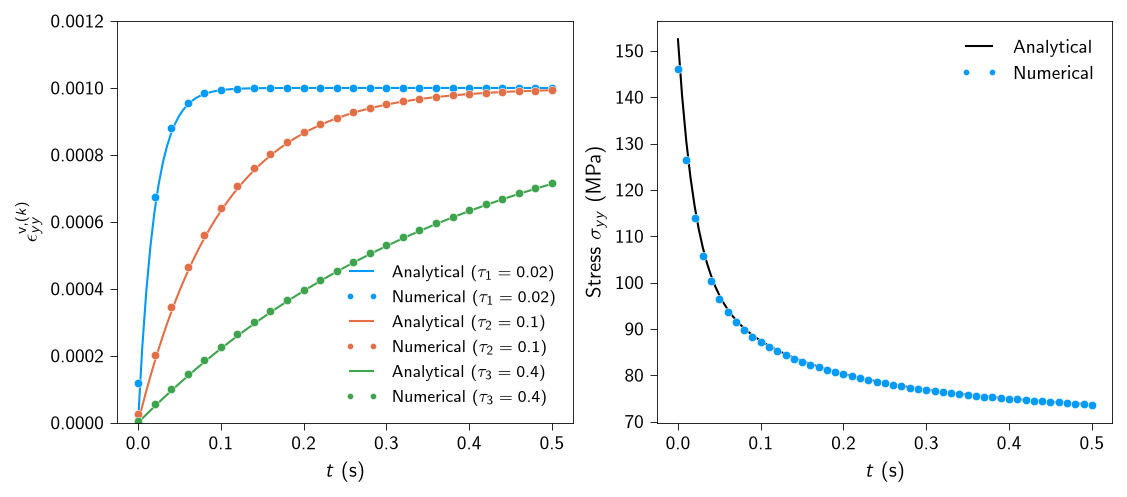

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.2), layout="constrained")

for k in range(mat.n_branches):
    tau_k = float(mat.tau_branches[k])
    sol_v_k = prestrain * (1.0 - np.exp(-np.asarray(time_domain) / tau_k))
    axs[0].plot(
        time_domain,
        sol_v_k,
        ls="-",
        color=f"C{k}",
        label=rf"Analytical ($\tau_{k + 1}={tau_k}$)",
    )
    axs[0].plot(
        time_domain,
        avg_vstrain_yy[:, k],
        marker="o",
        markevery=4,
        ls="",
        color=f"C{k}",
        label=rf"Numerical ($\tau_{k + 1}={tau_k}$)",
    )

axs[0].set_xlabel("$t$ (s)")
axs[0].set_ylabel(r"$\epsilon_{yy}^{\mathrm{v},(k)}$")
axs[0].set_ylim(0, 1.2 * prestrain)
axs[0].legend(frameon=False, fontsize=8)

axs[1].plot(time_domain, sol_sig_yy, ls="-", color="k", label="Analytical")
axs[1].plot(
    time_domain,
    avg_stress_yy,
    marker="o",
    markevery=2,
    ls="",
    label="Numerical",
)
axs[1].set_xlabel(r"$t$ (s)")
axs[1].set_ylabel(r"Stress $\sigma_{yy}$ (MPa)")
axs[1].legend(loc="upper right", frameon=False)

plt.show()